# Bibliotecas

In [224]:
# ! pip install statsmodels -U
# !pip install pmdarima

In [ ]:
import os
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from statsmodels.tsa.stattools import adfuller
from pmdarima.arima import ndiffs, auto_arima
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.arima.model import ARIMA
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error

# Dataset

In [ ]:
data_dir = '/content/drive/MyDrive/Datasets/NASA Acoustics and Vibration Database/2nd_test/2nd_test'
df_rolamento = pd.DataFrame()

for filename in os.listdir(data_dir):
    dataset = pd.read_csv(os.path.join(data_dir, filename), sep='\t')
    dataset_mean_abs = np.array(dataset.abs().mean())
    dataset_mean_abs = pd.DataFrame(dataset_mean_abs.reshape(1,4))
    dataset_mean_abs.index = [filename]
    df_rolamento = df_rolamento.append(dataset_mean_abs)

df_rolamento.columns = ['bearing_1','bearing_2','bearing_3','bearing_4']

## Ajuste do dataset

In [ ]:
df_rolamento.index = pd.to_datetime(df_rolamento.index,
                                    format='%Y.%m.%d.%H.%M.%S').sort_values()
                                    
df_rolamento.drop(columns=(['bearing_2','bearing_3','bearing_4']), inplace=True)

In [ ]:
pico_1 = df_rolamento.loc[pd.to_datetime('2004-02-19 04:12:39')][0].round(2)

pico_1

0.42

In [ ]:
pico_2 = df_rolamento.loc[pd.to_datetime('2004-02-19 05:32:39')][0].round(2)

pico_2

0.45

In [ ]:
df = df_rolamento.loc[:'2004-02-19 03:32:39'].copy()

df

,bearing_1
2004-02-12 10:32:39,0.061630
2004-02-12 10:42:39,0.058333
2004-02-12 10:52:39,0.061231
2004-02-12 11:02:39,0.058995
2004-02-12 11:12:39,0.062599
...,...
2004-02-19 02:52:39,0.139824
2004-02-19 03:02:39,0.179450
2004-02-19 03:12:39,0.153324
2004-02-19 03:22:39,0.228029


## Limites (3 sigma)

In [ ]:
media = df['bearing_1'].mean()

media

0.07738040915927043

In [ ]:
desv_pad = df['bearing_1'].std()

desv_pad

0.026222698066080404

### Limite superior

In [ ]:
lim_sup = (3 * desv_pad + media).round(2)

lim_sup

0.16

## Análise gráfica

Text(2004-02-13 00:00:00, 0.16104850335751164, '0.15604850335751164')

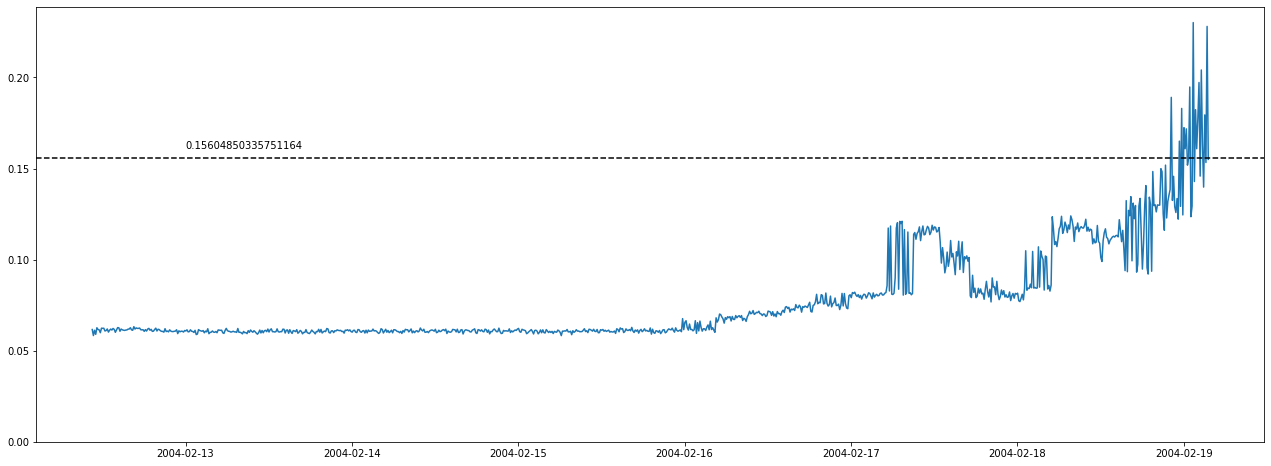

In [ ]:
ax = sns.lineplot(data=df,
                  x=df.index,
                  y='bearing_1')

ax.figure.set_size_inches(22,8)
ax.set_ylim(0)
ax.set_ylabel(ylabel=None)
ax.set_xlabel(xlabel=None)

ax.axhline(lim_sup, color='black', linestyle='--')

ax.annotate(s=str(lim_sup),
            xy=(pd.to_datetime('2004-02-13'), lim_sup),
            xytext=(pd.to_datetime('2004-02-13'), lim_sup + 0.005))

# Teste de estacionariedade

## Teste de Dickey-Fuller

In [ ]:
stat_t = adfuller(df.dropna())[0]
p_valor = adfuller(df.dropna())[1]

valor_critico_1 = adfuller(df.dropna())[4].get('1%')
valor_critico_5 = adfuller(df.dropna())[4].get('5%')
valor_critico_10 = adfuller(df.dropna())[4].get('10%')

significancia= 0.05
# Se a significância for 1% ou 10% é necessário
# alterar a condicional no if

if valor_critico_5 <= stat_t and significancia <= p_valor:
    print('Hipótese nula aceita'
          '\nSérie temporal não estacionária')
else:
    print('Hipótese nula rejeitada'
          '\nSérie temporal estacionária')

Hipótese nula aceita
Série temporal não estacionária


## Autocorrelação

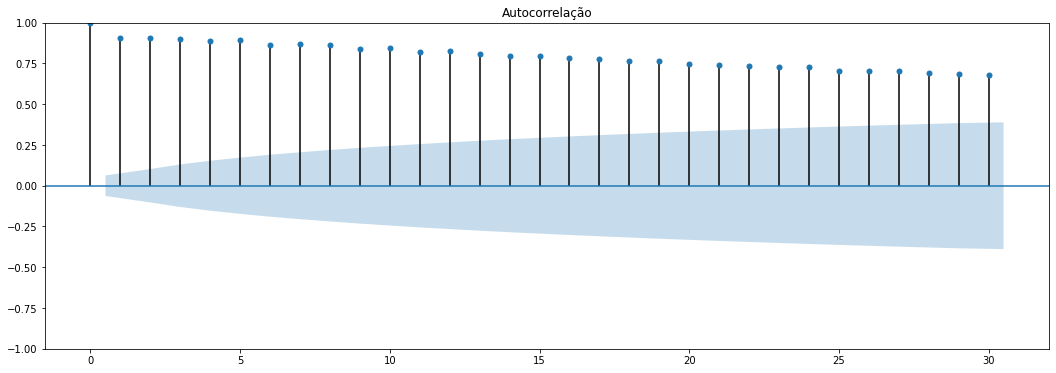

In [ ]:
autocorr = plot_acf(df, title='Autocorrelação')
autocorr.set_figheight(6)
autocorr.set_figwidth(18)
plt.show()

## Autocorrelação parcial

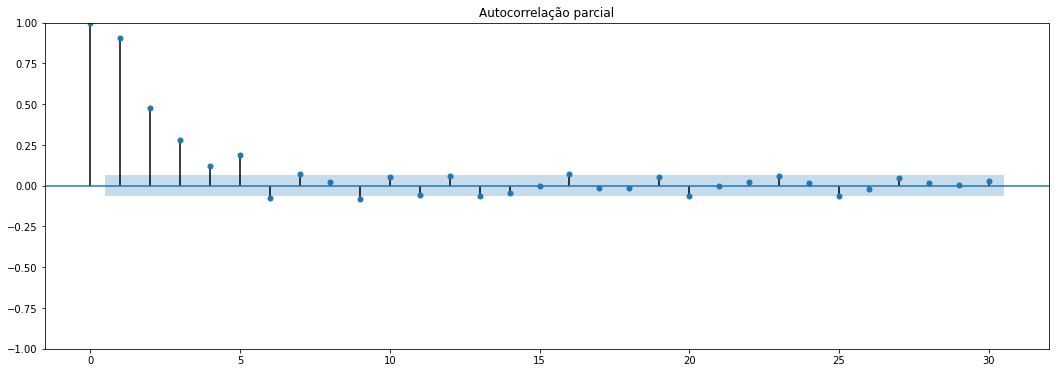

In [ ]:
autocorr_parc = plot_pacf(df,
                          title='Autocorrelação parcial',
                          method='ywm')
autocorr_parc.set_figheight(6)
autocorr_parc.set_figwidth(18)
plt.show()

## Diferenciação

In [ ]:
ndiffs(df, test='adf')

1

# ARIMA

## Parâmetros p, d, q

In [ ]:
auto_arima = auto_arima(df)

auto_arima

ARIMA(order=(2, 1, 5), scoring_args={}, suppress_warnings=True)

In [ ]:
modelo = ARIMA(endog=df,
               order=(2, 1, 5),
               freq='10min')

results = modelo.fit()

# print(results.summary())

/usr/local/lib/python3.8/dist-packages/statsmodels/tsa/base/tsa_model.py:471: ValueWarning: No frequency information was provided, so inferred frequency 10T will be used.
  self._init_dates(dates, freq)


## Análise dos resíduos

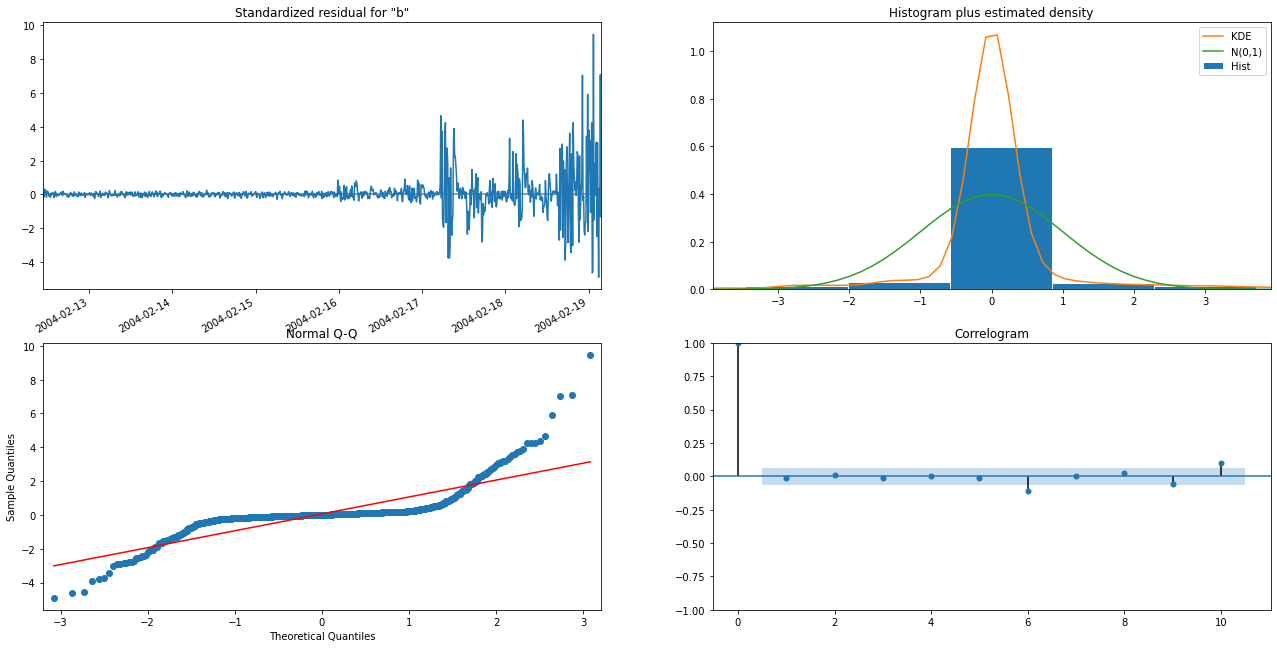

In [ ]:
results.plot_diagnostics(figsize=(22,12));

# Previsão de valores



## Treino e teste

In [ ]:
tam_treino = int(round(len(df) * 0.7, 0))

In [ ]:
train = df.iloc[:tam_treino]

test = df.iloc[tam_treino:]

## Interpolação

#### Modelo de previsão

In [ ]:
pred = results.get_prediction(start=test.index[0],
                              dynamic=False)

### Intervalo de confiança

In [ ]:
pred_ic = pred.conf_int()

### Análise gráfica

Text(2004-02-19 06:02:39, 0.45, 'pico 2 ➜ 0.45')

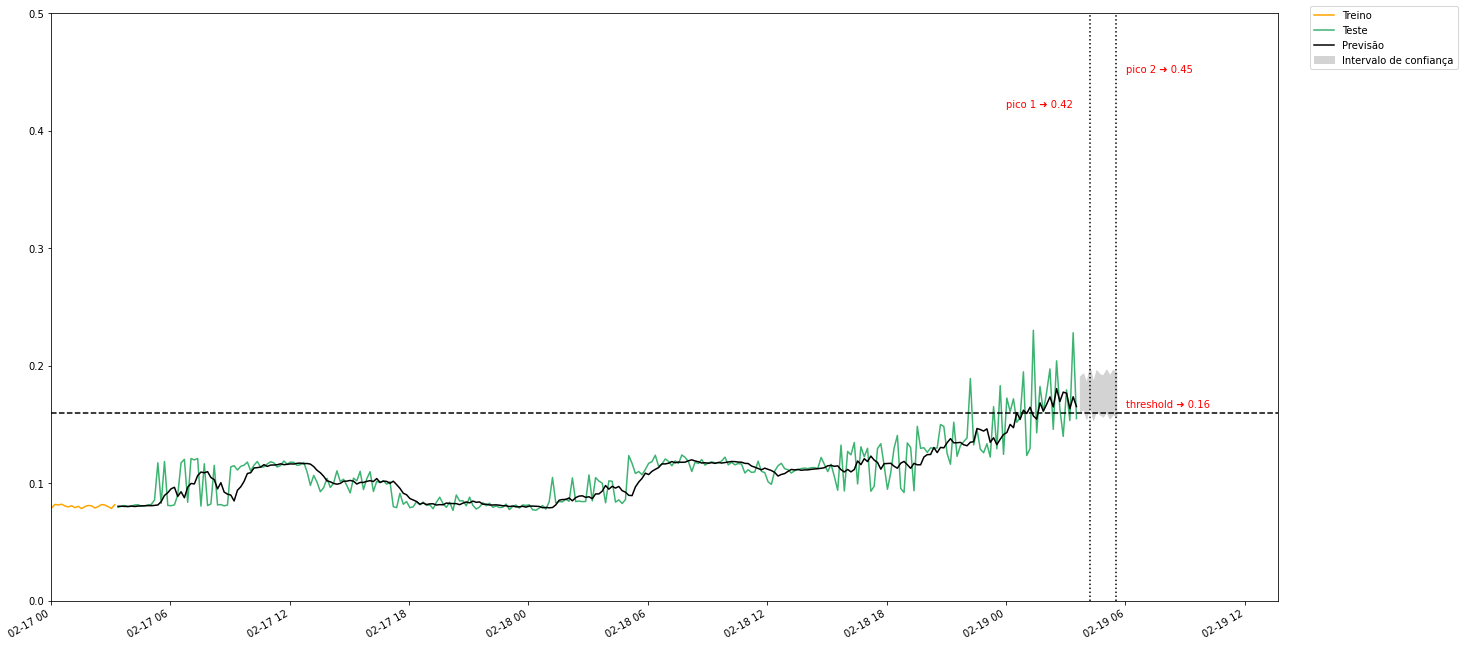

In [ ]:
ax = train.plot(color='orange')

test.plot(ax=ax, color='mediumseagreen')

pred.predicted_mean.plot(ax=ax, color='k')

ax.fill_between(pred_ic.index,
                pred_ic.iloc[:, 0],
                pred_ic.iloc[:, 1],
                color='lightgrey')

ax.figure.set_size_inches(22,12)
ax.set_xlabel(None)
ax.legend(labels=['Treino',
                  'Teste',
                  'Previsão',
                  'Intervalo de confiança'],
                   bbox_to_anchor=(1.15, 1.02))

ax.set_xlim(pd.to_datetime('2004-02-17'))
ax.set_ylim(0, 0.5)

ax.axvline('2004-02-19 04:12:39', color='black', linestyle=':')

ax.axvline('2004-02-19 05:32:39', color='black', linestyle=':')

ax.axhline(lim_sup, color='black', linestyle='--')

ax.annotate(s='threshold ➜ ' + str(lim_sup),
            xy=(pd.to_datetime('2004-02-19'), lim_sup),
            xytext=(pd.to_datetime('2004-02-19 06:02:39'), lim_sup + 0.005),
            color='r')

ax.annotate(s='pico 1 ➜ ' + str(pico_1),
            xy=(pd.to_datetime('2004-02-19'), pico_1),
            xytext=(pd.to_datetime('2004-02-19'), pico_1),
            color='r')

ax.annotate(s='pico 2 ➜ ' + str(pico_2),
            xy=(pd.to_datetime('2004-02-19'), pico_2),
            xytext=(pd.to_datetime('2004-02-19 06:02:39'), pico_2),
            color='r')

### Acurácia do modelo

#### Raiz do erro quadrático médio

In [ ]:
from math import sqrt

rmse = sqrt(mean_squared_error(test,
                         pred.predicted_mean))

rmse

0.013917307667023707

#### Coeficiente de determinação (r²)

In [ ]:
r_squared = r2_score(test,
                     pred.predicted_mean)

r_squared

0.7295847773610735

#### Erro médio absoluto

In [ ]:
mae = mean_absolute_error(test,
                          pred.predicted_mean)

mae

0.009094364674887943

## Extrapolação

In [ ]:
pred_uc = results.get_forecast(steps=12) # Em cada passo deve ser considerado 10 min

### Intervalo de confiança

In [ ]:
pred_ic = pred_uc.conf_int()

### Análise gráfica

Text(2004-02-19 06:02:39, 0.45, 'pico 2 ➜ 0.45')

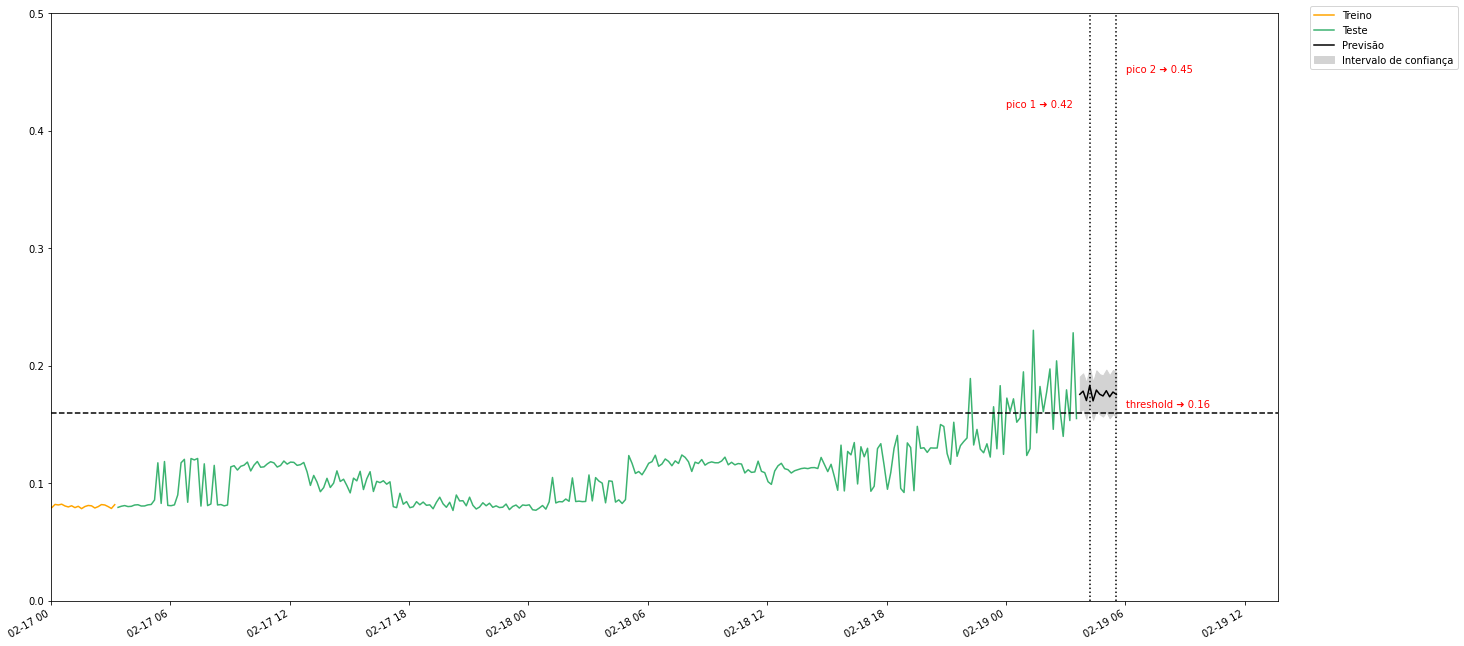

In [ ]:
fig, ax = plt.subplots(figsize=(22, 12))

train.plot(ax=ax, color='orange')

test.plot(ax=ax, color='mediumseagreen')

pred_uc.predicted_mean.plot(ax=ax, color='k')

ax.fill_between(pred_ic.index,
                pred_ic.iloc[:, 0],
                pred_ic.iloc[:, 1],
                color='lightgrey')

ax.legend(labels=['Treino', 'Teste', 'Previsão', 'Intervalo de confiança'],
          bbox_to_anchor=(1.15, 1.02))

ax.set_xlim(pd.to_datetime('2004-02-17'))
ax.set_ylim(0, 0.5)

ax.axvline('2004-02-19 04:12:39', color='black', linestyle=':')

ax.axvline('2004-02-19 05:32:39', color='black', linestyle=':')

ax.axhline(lim_sup, color='black', linestyle='--')

ax.annotate(s='threshold ➜ ' + str(lim_sup),
            xy=(pd.to_datetime('2004-02-19'), lim_sup),
            xytext=(pd.to_datetime('2004-02-19 06:02:39'), lim_sup + 0.005),
            color='r')

ax.annotate(s='pico 1 ➜ ' + str(pico_1),
            xy=(pd.to_datetime('2004-02-19'), pico_1),
            xytext=(pd.to_datetime('2004-02-19'), pico_1),
            color='r')

ax.annotate(s='pico 2 ➜ ' + str(pico_2),
            xy=(pd.to_datetime('2004-02-19'), pico_2),
            xytext=(pd.to_datetime('2004-02-19 06:02:39'), pico_2),
            color='r')